# 06 — Multi-Product Formulas with `qiskit-addon-mpf`

**Multi-product formulas (MPFs)** reduce the Trotter error of simulated Hamiltonian dynamics. The *Trotter error* is the difference between a product-formula circuit and the exact time evolution.

An MPF does not use one very deep Trotter circuit. It runs several **shallower** Trotter circuits with different numbers of steps $k_j$. It then combines their expectation values with coefficients $x_j$. The combination cancels the leading orders of the Trotter error.

The package `qiskit-addon-mpf` (version 0.3.0 here) computes these coefficients:

* **Static MPFs** (`qiskit_addon_mpf.static` [[6]](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.static.html)): time-independent coefficients from a small linear system. The system depends only on the $k_j$ and on the order of the product formula.
* **Dynamic MPFs** (`qiskit_addon_mpf.dynamic` [[8]](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.dynamic.html)): time-dependent coefficients. They minimize the distance to the exact evolution. The required overlaps are computed classically with tensor networks (quimb or TeNPy backends from the `[dynamic]` extra).
* **Cost functions** (`qiskit_addon_mpf.costs` [[7]](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.costs.html)): exact, sum-of-squares and Frobenius-norm optimization problems, built with `cvxpy`.

**Based on**

* the getting-started tutorial [[1]](https://qiskit.github.io/qiskit-addon-mpf/tutorials/01_getting_started.html),
* the how-to guides on choosing the Trotter steps [[2]](https://qiskit.github.io/qiskit-addon-mpf/how_tos/choose_trotter_steps.html) and on the approximate model [[3]](https://qiskit.github.io/qiskit-addon-mpf/how_tos/using_approximate_model.html),
* the IBM Quantum tutorial on MPFs [[4]](https://quantum.cloud.ibm.com/docs/en/tutorials/multi-product-formula), for the dynamic MPF with the layer-wise backend.

The model (a 6-qubit tilted-field Ising chain) and the hand-built Trotter circuits are our own example.

Installation:

```bash
pip install "qiskit-addon-mpf[dynamic]"
```

**Contents**

1. Theory: Trotter error and multi-product formulas
2. The model: a tilted-field Ising chain and exact reference dynamics
3. Building Trotter circuits (and a pitfall with `PauliEvolutionGate`)
4. How Trotter error scales with the number of steps
5. Static MPFs: `setup_static_lse` and the cost functions
6. Choosing the Trotter steps $k_j$
7. Static MPF vs. single Trotter circuits vs. exact, with `StatevectorEstimator`
8. Dynamic MPFs with the quimb `LayerwiseEvolver` backend
9. Comparison: error vs. time
10. Summary and references

## 1. Theory: Trotter error and multi-product formulas

Consider a Hamiltonian $H=\sum_{a} H_a$ whose terms do not commute. Then $e^{-iHt}$ cannot be implemented directly. A **product formula** $S(\delta t)$ approximates one short time step. Two examples:

* First-order Lie–Trotter: $S_1(\delta t)=\prod_a e^{-iH_a\delta t}$. The error per step is $O(\delta t^2)$.
* Second-order (symmetric) Suzuki–Trotter: $S_2(\delta t)=\prod_{a=1}^{m} e^{-iH_a\delta t/2}\prod_{a=m}^{1} e^{-iH_a\delta t/2}$. The error per step is $O(\delta t^3)$.

With $k$ steps of size $\delta t = t/k$, we get $U_k(t)=S(t/k)^k$. For a formula of order $\chi$, the error has the expansion

$$
U_k(t) = e^{-iHt} + \sum_{n\ge 0} \frac{E_{\chi+ s n}(t)}{k^{\chi+s n}},
$$

where $s=2$ for symmetric formulas (only even powers remain) and $s=1$ otherwise. A single formula needs a large $k$ for a small error. A large $k$ means a deep circuit, and on noisy hardware depth is the expensive resource.

**Multi-product formula.** We take several step counts $k_1<k_2<\dots<k_r$ and form a linear combination:

$$
\mu(t) = \sum_{j=1}^{r} x_j\, U_{k_j}(t)\qquad\text{or, for expectation values,}\qquad
\langle O\rangle_{\text{MPF}} = \sum_j x_j \langle O\rangle_{k_j}.
$$

The conditions on the coefficients are:

* $\sum_j x_j=1$, so that the exact part is kept,
* $\sum_j x_j / k_j^{\chi+s(i-1)} = 0$ for $i=1,\dots,r-1$, so that the first $r-1$ error orders cancel.

Together they form a linear system $A x = b$:

$$
A_{0,j}=1,\qquad A_{i>0,j}=k_j^{-(\chi+s(i-1))},\qquad b=(1,0,\dots,0)^T .
$$

This is the **static MPF** [[6]](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.static.html). The coefficients can be negative. So statistical and hardware noise are amplified by about $\|x\|_1=\sum_j|x_j|$ [[5]](https://qiskit.github.io/qiskit-addon-mpf/explanations/mpf_stability.html). Good choices of $k_j$ keep $\|x\|_1$ small. The **approximate** cost functions give up exact error cancellation in exchange for a bounded $\|x\|_1$.

The static derivation assumes that the error expansion converges. This roughly needs $t/k_j\lesssim 1$. **Dynamic MPFs** [[8]](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.dynamic.html), [[4]](https://quantum.cloud.ibm.com/docs/en/tutorials/multi-product-formula) drop this assumption. At each time $t$ they choose the $x(t)$ that minimizes the Frobenius distance between the MPF state and the exact state $\rho(t)$:

$$
\min_{x}\; \Big\|\rho(t) - \sum_j x_j \rho_{k_j}(t)\Big\|_F^2 = 1 + \sum_{ij} M_{ij}x_ix_j - 2\sum_i L_i x_i ,
\quad M_{ij}=\mathrm{Tr}(\rho_{k_i}\rho_{k_j}),\; L_i=\mathrm{Tr}(\rho\,\rho_{k_i}),
$$

subject to $\sum_j x_j = 1$ and $\|x\|_1\le c$. $M$ and $L$ come from a classical tensor-network calculation. This calculation is cheap for short times and moderate entanglement.

## 2. The model and exact reference

We use a small **tilted-field Ising chain** with open boundaries on $N=6$ qubits:

$$
H = J\sum_{i} Z_iZ_{i+1} + h_x\sum_i X_i + h_z \sum_i Z_i ,\qquad J=1,\; h_x=0.8,\; h_z=0.3 .
$$

We split $H$ into four groups of mutually commuting terms:

1. $ZZ$ on even bonds,
2. $ZZ$ on odd bonds,
3. the $X$ field,
4. the $Z$ field.

Each group can be exponentiated exactly with one layer of gates. The initial state is the Néel state $|010101\rangle$. The observable is the magnetization $\langle M_z\rangle=\frac1N\sum_i\langle Z_i\rangle$.

With only 6 qubits, `scipy.linalg.expm` gives the exact evolution $e^{-iHt}$ directly.

In [1]:
import time as _time
import warnings
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp, Statevector, Operator
from qiskit.primitives import StatevectorEstimator

import qiskit, qiskit_addon_mpf  # noqa
from importlib.metadata import version
print("qiskit", qiskit.__version__, "| qiskit-addon-mpf", version("qiskit-addon-mpf"),
      "| quimb", version("quimb"), "| cvxpy", version("cvxpy"))
warnings.filterwarnings("ignore", category=Warning, module="scipy")

qiskit 2.5.2 | qiskit-addon-mpf 0.3.0 | quimb 1.11.2 | cvxpy 1.7.5


In [2]:
N, J, hx, hz = 6, 1.0, 0.8, 0.3

groups = [
    SparsePauliOp.from_sparse_list([("ZZ", (i, i + 1), J) for i in range(0, N - 1, 2)], N),  # even bonds
    SparsePauliOp.from_sparse_list([("ZZ", (i, i + 1), J) for i in range(1, N - 1, 2)], N),  # odd bonds
    SparsePauliOp.from_sparse_list([("X", (i,), hx) for i in range(N)], N),                  # X field
    SparsePauliOp.from_sparse_list([("Z", (i,), hz) for i in range(N)], N),                  # Z field
]
H = sum(groups).simplify()
observable = SparsePauliOp.from_sparse_list([("Z", (i,), 1 / N) for i in range(N)], N)

def initial_circuit():
    qc = QuantumCircuit(N)
    for i in range(1, N, 2):   # Neel state |010101> (qubit 0 = leftmost site)
        qc.x(i)
    return qc

psi0 = Statevector(initial_circuit())
Hmat = H.to_matrix()
Omat = observable.to_matrix()

def exact_ev(t):
    psi = expm(-1j * t * Hmat) @ psi0.data
    return float(np.real(np.vdot(psi, Omat @ psi)))

times = np.round(np.arange(0.0, 3.01, 0.1), 2)
exact_vals = np.array([exact_ev(t) for t in times])
print(H)

SparsePauliOp(['IIIIZZ', 'IIZZII', 'ZZIIII', 'IIIZZI', 'IZZIII', 'IIIIIX', 'IIIIXI', 'IIIXII', 'IIXIII', 'IXIIII', 'XIIIII', 'IIIIIZ', 'IIIIZI', 'IIIZII', 'IIZIII', 'IZIIII', 'ZIIIII'],
              coeffs=[1. +0.j, 1. +0.j, 1. +0.j, 1. +0.j, 1. +0.j, 0.8+0.j, 0.8+0.j, 0.8+0.j,
 0.8+0.j, 0.8+0.j, 0.8+0.j, 0.3+0.j, 0.3+0.j, 0.3+0.j, 0.3+0.j, 0.3+0.j,
 0.3+0.j])


## 3. Building Trotter circuits

A small helper returns the sequence of `(group, time)` layers for one symmetric second-order Suzuki–Trotter step. It also implements the Suzuki recursion for higher orders. Each layer becomes a `PauliEvolutionGate` [[10]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.PauliEvolutionGate) of one commuting group. The gate is then **decomposed** into native `rzz`/`rx`/`rz` rotations.

> **Pitfall.** `Statevector`, `Operator` and therefore `StatevectorEstimator` simulate an *undecomposed*
> `PauliEvolutionGate` with its `to_matrix()` method. This method returns the **exact** exponential $e^{-iHt}$,
> *not* the Trotterized circuit. So `PauliEvolutionGate(H, t, synthesis=SuzukiTrotter(...))` simulated directly
> shows zero Trotter error. Always decompose (or transpile) Trotter circuits before you simulate them with these tools. The next cell shows the effect.

In [3]:
from qiskit.synthesis import SuzukiTrotter

g = PauliEvolutionGate(H, 1.0, synthesis=SuzukiTrotter(order=2, reps=2))
qc_g = initial_circuit(); qc_g.append(g, range(N))
ev_gate = Statevector(qc_g).expectation_value(observable).real
ev_decomp = Statevector(qc_g.decompose(reps=2)).expectation_value(observable).real
print(f"exact          : {exact_ev(1.0):+.6f}")
print(f"undecomposed   : {ev_gate:+.6f}   <- identical to exact (to_matrix is the exact exponential)")
print(f"decomposed k=2 : {ev_decomp:+.6f}   <- the real 2-step Trotter result")

exact          : -0.095280
undecomposed   : -0.095280   <- identical to exact (to_matrix is the exact exponential)
decomposed k=2 : -0.100689   <- the real 2-step Trotter result


OrderedDict([('rx', 24), ('rzz', 20), ('rz', 12), ('x', 3)]) depth 15


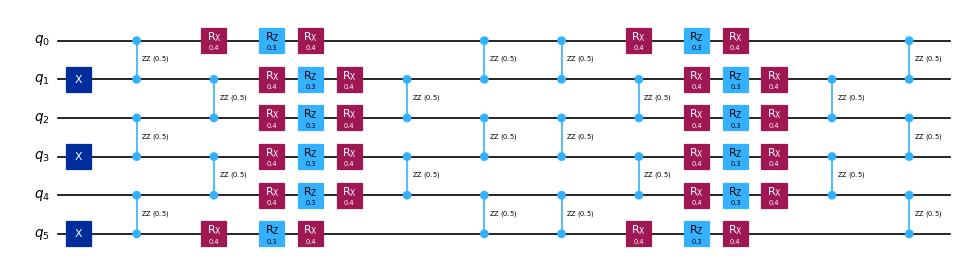

In [4]:
def suzuki_layers(tau, order=2):
    # List of (group_index, duration) for one Suzuki-Trotter step of length tau.
    if order == 2:
        m = len(groups) - 1
        return ([(g, tau / 2) for g in range(m)] + [(m, tau)]
                + [(g, tau / 2) for g in reversed(range(m))])
    p = 1 / (4 - 4 ** (1 / (order - 1)))       # Suzuki recursion S_{2k} from S_{2k-2}
    lo = order - 2
    return (suzuki_layers(p * tau, lo) * 2 + suzuki_layers((1 - 4 * p) * tau, lo)
            + suzuki_layers(p * tau, lo) * 2)

def layer_circuit(g, tau):
    qc = QuantumCircuit(N)
    qc.append(PauliEvolutionGate(groups[g], tau), range(N))
    return qc.decompose()               # -> native rzz / rx / rz gates

def step_layers(tau, order=2):
    return [layer_circuit(g, x) for g, x in suzuki_layers(tau, order)]

def trotter_circuit(t, k, order=2):
    # Neel state followed by k Suzuki-Trotter steps of size t/k.
    qc = initial_circuit()
    for _ in range(k):
        for layer in step_layers(t / k, order):
            qc.compose(layer, inplace=True)
    return qc

qc_demo = trotter_circuit(1.0, 2)
print(qc_demo.count_ops(), "depth", qc_demo.depth())
qc_demo.draw("mpl", fold=-1, scale=0.6)

## 4. How Trotter error scales with $k$

At fixed time $t=1.5$, the error of the second-order formula should fall as $k^{-2}$. The MPF uses this scaling. The error depends on $k$ in a known way, so a linear combination over different $k$ can cancel it.

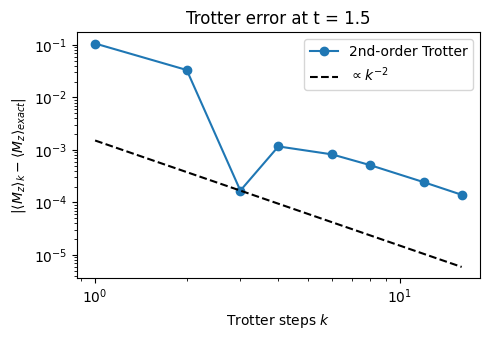

In [5]:
estimator = StatevectorEstimator()
t_fix = 1.5
k_scan = [1, 2, 3, 4, 6, 8, 12, 16]
pubs = [(trotter_circuit(t_fix, k), observable) for k in k_scan]
evs_scan = np.array([r.data.evs for r in estimator.run(pubs).result()])
err_scan = np.abs(evs_scan - exact_ev(t_fix))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.loglog(k_scan, err_scan, "o-", label="2nd-order Trotter")
ax.loglog(k_scan, err_scan[2] * (k_scan[2] / np.array(k_scan)) ** 2, "k--", label=r"$\propto k^{-2}$")
ax.set_xlabel("Trotter steps $k$"); ax.set_ylabel(r"$|\langle M_z\rangle_k - \langle M_z\rangle_{exact}|$")
ax.set_title(f"Trotter error at t = {t_fix}"); ax.legend(); plt.tight_layout(); plt.show()

## 5. Static MPFs: the linear system and cost functions

`setup_static_lse(trotter_steps, order=..., symmetric=...)` [[6]](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.static.html) returns an `LSE` named tuple with `A` and `b`. LSE stands for linear system of equations. Our formula is second order and symmetric, so we use `order=2, symmetric=True`. The `costs` module [[7]](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.costs.html) in version 0.3.0 provides:

| function | what it solves |
|---|---|
| `LSE.solve()` | analytic $x=A^{-1}b$ (exact static MPF) |
| `setup_exact_problem(lse)` | same solution, posed as a `cvxpy` problem (minimize $\|x\|_1$ s.t. $Ax=b$) |
| `setup_sum_of_squares_problem(lse, max_l1_norm=...)` | approximate: minimize $\sum_i (A_i x - b_i)^2$ s.t. $\sum x=1$, $\|x\|_1\le c$ |
| `setup_frobenius_problem(lse, max_l1_norm=...)` | approximate, meant for the **dynamic** LSE (Gram matrix and overlaps) |

Each `setup_*` function returns `(problem, x)`. Call `problem.solve()` and read `x.value`. The approximate model is described in the how-to [[3]](https://qiskit.github.io/qiskit-addon-mpf/how_tos/using_approximate_model.html).

In [6]:
from qiskit_addon_mpf.static import setup_static_lse
from qiskit_addon_mpf.costs import (setup_exact_problem, setup_sum_of_squares_problem,
                                    setup_frobenius_problem)

trotter_steps = [2, 3, 4]
lse = setup_static_lse(trotter_steps, order=2, symmetric=True)
print("A =\n", lse.A, "\nb =", lse.b)

coeffs_exact = lse.solve()
print("\nanalytic   x =", coeffs_exact, " sum =", coeffs_exact.sum(), " L1 =", np.abs(coeffs_exact).sum())

problem, x = setup_exact_problem(lse)
problem.solve()
print("cvxpy exact x =", x.value)

problem, x = setup_sum_of_squares_problem(lse, max_l1_norm=3.0)
problem.solve()
coeffs_approx = x.value
print("sum-of-squares (L1<=3) x =", coeffs_approx, " L1 =", np.abs(coeffs_approx).sum())

A =
 [[1.         1.         1.        ]
 [0.25       0.11111111 0.0625    ]
 [0.0625     0.01234568 0.00390625]] 
b = [1. 0. 0.]

analytic   x = [ 0.26666667 -2.31428571  3.04761905]  sum = 1.0  L1 = 5.62857142857143
cvxpy exact x = [ 0.26666667 -2.31428571  3.04761905]
sum-of-squares (L1<=3) x = [-0.07803754 -0.92196246  2.        ]  L1 = 3.0


The exact coefficients have $\|x\|_1\approx 5.6$. So noise in each $\langle O\rangle_{k_j}$ is amplified about 5.6 times. The approximate solution limits the L1 norm to 3. It cancels less of the error, but it is much less sensitive to shot noise (the statistical error from a finite number of measurements).

## 6. Choosing the Trotter steps $k_j$

The how-to guide [[2]](https://qiskit.github.io/qiskit-addon-mpf/how_tos/choose_trotter_steps.html) gives these rules:

* The deepest circuit you can run reliably limits $k_{\max}$.
* $k_{\min}$ should satisfy $t/k_{\min}\lesssim 1$. Otherwise the error expansion behind static MPFs breaks down.
* Avoid sets where a coefficient is $\approx 0$ (that circuit is wasted) or where one coefficient dominates.
* Keep $\|x\|_1$ small. Rank candidate sets by the re-weighted norm $\sum_j |x_j|/k_j^{2\chi}$.

`setup_static_lse` also accepts a `cvxpy.Parameter`. So one LSE can be reused while the $k_j$ change during the scan.

In [7]:
import itertools
import cvxpy as cp

ks_param = cp.Parameter(3, integer=True)
lse_p = setup_static_lse(ks_param, order=2, symmetric=True)

rows = []
for ks in itertools.combinations(range(2, 13), 3):
    ks_param.value = np.array(ks)
    c = lse_p.solve()
    if np.any(np.isclose(c, 0.0, atol=0.01)):
        continue
    l1 = np.abs(c).sum()
    if l1 > 6:
        continue
    rew = np.sum(np.abs(c) / np.array(ks) ** (2 * 2))
    rows.append((ks, l1, rew, c))

rows.sort(key=lambda r: r[2])
print(f"{'k_j':>12} {'L1':>7} {'reweighted':>11}   coefficients")
for ks, l1, rew, c in rows[:8]:
    print(f"{str(ks):>12} {l1:7.3f} {rew:11.2e}   {np.round(c, 3)}")

         k_j      L1  reweighted   coefficients
  (3, 8, 12)   2.862    4.55e-04   [ 0.011 -0.931  1.92 ]
  (4, 9, 12)   4.204    4.88e-04   [ 0.031 -1.602  2.571]
  (4, 8, 12)   3.133    5.21e-04   [ 0.042 -1.067  2.025]
  (3, 7, 12)   2.264    5.26e-04   [ 0.015 -0.632  1.617]
  (5, 9, 12)   4.719    5.67e-04   [ 0.094 -1.86   2.766]
  (3, 8, 11)   3.613    6.38e-04   [ 0.013 -1.307  2.293]
  (4, 7, 12)   2.532    6.38e-04   [ 0.061 -0.766  1.705]
  (5, 8, 12)   3.626    6.41e-04   [ 0.135 -1.313  2.178]


Larger $k_j$ give smaller re-weighted norms, but they also mean deeper circuits. We keep $k=(2,3,4)$, so the circuits stay short and the differences between methods stay visible. With these values, $t/k_{\min}=t/2$. So the static MPF should work well up to $t\approx 2$ and start to fail beyond that. This failure is the reason for dynamic MPFs.

## 7. Static MPF vs. single Trotter circuits vs. exact

For each time $t$ we build one Trotter circuit per $k_j$. We estimate $\langle M_z\rangle$ with `StatevectorEstimator` [[11]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator). All circuits go into one `run` call as a list of PUBs (primitive unified blocs: tuples of circuit and observable). Then we combine the results with `evs @ coeffs`.

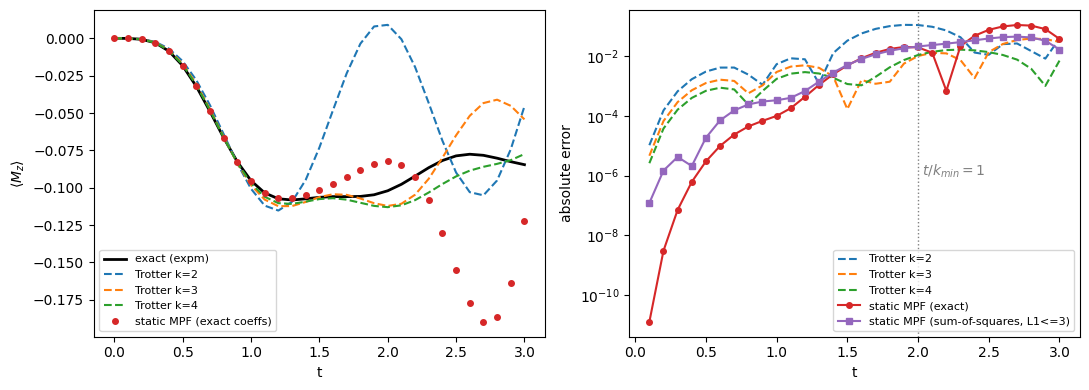

In [8]:
pubs = [(trotter_circuit(t, k), observable) for t in times for k in trotter_steps]
res = estimator.run(pubs).result()
evs = np.array([r.data.evs for r in res]).reshape(len(times), len(trotter_steps))

mpf_static = evs @ coeffs_exact
mpf_static_approx = evs @ coeffs_approx

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(times, exact_vals, "k-", lw=2, label="exact (expm)")
for j, k in enumerate(trotter_steps):
    ax[0].plot(times, evs[:, j], "--", label=f"Trotter k={k}")
ax[0].plot(times, mpf_static, "o", ms=4, label="static MPF (exact coeffs)")
ax[0].set_xlabel("t"); ax[0].set_ylabel(r"$\langle M_z\rangle$"); ax[0].legend(fontsize=8)

for j, k in enumerate(trotter_steps):
    ax[1].semilogy(times[1:], np.abs(evs[1:, j] - exact_vals[1:]), "--", label=f"Trotter k={k}")
ax[1].semilogy(times[1:], np.abs(mpf_static - exact_vals)[1:], "o-", ms=4, label="static MPF (exact)")
ax[1].semilogy(times[1:], np.abs(mpf_static_approx - exact_vals)[1:], "s-", ms=4, label="static MPF (sum-of-squares, L1<=3)")
ax[1].axvline(2.0, color="gray", ls=":", lw=1); ax[1].text(2.03, 1e-6, r"$t/k_{min}=1$", color="gray")
ax[1].set_xlabel("t"); ax[1].set_ylabel("absolute error"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

For small $t$, the static MPF is more accurate than every single circuit, including the deepest one ($k=4$). The table in Section 9 shows errors about 17 to $10^4$ times smaller than the best single circuit for $t \le 1$. All circuits in the MPF have at most 4 Trotter steps. When $t/k_{\min}$ grows past about 1, the error expansion is no longer accurate. The static combination can then be *worse* than the best single circuit.

## 8. Dynamic MPFs (quimb backend)

`setup_dynamic_lse(trotter_steps, time, identity_factory, exact_evolver_factory, approx_evolver_factory, initial_state)` [[8]](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.dynamic.html) computes two quantities by tensor-network time evolution of an MPO (matrix product operator):

* the Gram matrix $M$, stored in `lse.A`,
* the overlap vector $L$, stored in `lse.b`.

We then pass the result to `setup_frobenius_problem`.

The `[dynamic]` extra installs quimb and TeNPy backends (`quimb_tebd`, `quimb_layers`, `quimb_circuit`, `tenpy_tebd`, `tenpy_layers`). The coefficients are only meaningful if the approximate evolver applies **exactly the same product formula** as the quantum circuits. So we use the **layer-wise** backend `qiskit_addon_mpf.backends.quimb_layers` [[9]](https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.backends.quimb_layers.html), as in the tutorials [[1]](https://qiskit.github.io/qiskit-addon-mpf/tutorials/01_getting_started.html), [[4]](https://quantum.cloud.ibm.com/docs/en/tutorials/multi-product-formula):

1. Take the layers of **one** Trotter step with time `1.0`. The backend rescales them by `dt`.
2. Convert each layer to a `LayerModel` with `LayerModel.from_quantum_circuit`. Split single-qubit layers into two models (`keep_only_odd=True/False`). Then TEBD (time-evolving block decimation) keeps updating even and odd bonds alternately.
3. Set `approx_evolver_factory = partial(LayerwiseEvolver, layers=..., split_opts=...)`. The backend supplies `dt=t/k_j` internally.
4. For the "exact" reference evolver, use a 4th-order Suzuki formula with a small fixed `dt=0.05`.
5. `identity_factory` returns an identity `MPOState`. `initial_state` is a quimb `MPS_neel_state`. Quimb site $i$ is qubit $i$, so this matches our `initial_circuit`: $|010101\rangle$.

> The tutorials build the layers with `generate_time_evolution_circuit` and `slice_by_gate_types` from `qiskit-addon-utils`.
> That package is not installed in this environment. Our hand-built layers from Section 3 serve the same purpose.

In [9]:
from qiskit_addon_mpf.backends import HAS_QUIMB
from qiskit_addon_mpf.backends.quimb_layers import LayerModel, LayerwiseEvolver
from qiskit_addon_mpf.backends.quimb_tebd import MPOState
from qiskit_addon_mpf.dynamic import setup_dynamic_lse
from quimb.tensor import MPO_identity, MPS_neel_state
print("quimb available:", bool(HAS_QUIMB))

def to_layer_models(layers):
    models = []
    for layer in layers:
        if layer.data[0].operation.num_qubits == 2:
            models.append(LayerModel.from_quantum_circuit(layer))
        else:  # single-qubit layer: split onto odd and even bonds
            models.append(LayerModel.from_quantum_circuit(layer, keep_only_odd=True))
            models.append(LayerModel.from_quantum_circuit(layer, keep_only_odd=False))
    return models

approx_models = to_layer_models(step_layers(1.0, order=2))   # template: one 2nd-order step, time 1
exact_models = to_layer_models(step_layers(1.0, order=4))    # template: one 4th-order step, time 1
print(len(approx_models), "approx layer models,", len(exact_models), "exact layer models")

split_opts = {"max_bond": 64, "cutoff": 1e-12}   # 64 = full MPO bond dim for 6 qubits
approx_evolver_factory = partial(LayerwiseEvolver, layers=approx_models, split_opts=split_opts)
exact_evolver_factory = partial(LayerwiseEvolver, layers=exact_models, dt=0.05, split_opts=split_opts)
identity_factory = lambda: MPOState(MPO_identity(N))
mps_initial_state = MPS_neel_state(N)
print("Neel MPS nonzero amplitude index:", np.flatnonzero(mps_initial_state.to_dense()), "->",
      format(int(np.flatnonzero(mps_initial_state.to_dense())[0]), f"0{N}b"), "(site 0 first)")

quimb available: True
10 approx layer models, 50 exact layer models
Neel MPS nonzero amplitude index: [21] -> 010101 (site 0 first)


We first look at one time point in detail. `lse.A` is the Gram matrix. Its entries are close to 1 because all states are similar. `lse.b` holds the overlaps with the exact state. Do **not** call `LSE.solve()` here, unlike in the static case. The dynamic LSE does not enforce $\sum x = 1$, so `solve()` raises a `ValueError`. Use a cost function instead.

In [10]:
t0 = _time.time()
lse_dyn = setup_dynamic_lse(trotter_steps, 1.5, identity_factory, exact_evolver_factory,
                            approx_evolver_factory, mps_initial_state)
print(f"setup_dynamic_lse took {_time.time() - t0:.1f}s")
print("M = lse.A =\n", np.real_if_close(lse_dyn.A), "\nL = lse.b =", np.real_if_close(lse_dyn.b))
try:
    lse_dyn.solve()
except ValueError as e:
    print("\nlse.solve() ->", type(e).__name__, ":", str(e)[:90], "...")

problem, x = setup_frobenius_problem(lse_dyn, max_l1_norm=3.0)
problem.solve()
print("\ndynamic coefficients at t=1.5:", x.value, " (static:", np.round(coeffs_exact, 3), ")")

setup_dynamic_lse took 7.6s
M = lse.A =
 [[1.         0.78899532 0.69219627]
 [0.78899532 1.         0.98559854]
 [0.69219627 0.98559854 1.        ]] 
L = lse.b = [0.57946323 0.93726312 0.98209007]

lse.solve() -> ValueError : This LSE does not enforce the sum of all coefficients to be equal to 1 which is required f ...

dynamic coefficients at t=1.5: [ 0.02660365 -1.          1.97339635]  (static: [ 0.267 -2.314  3.048] )


Now we scan over time. The dynamic coefficients depend on $t$, so we solve one small LSE per time point. Each point takes about 8 seconds at this size. If a solve fails, the code uses the static coefficients instead.

In [11]:
dyn_times = np.round(np.arange(0.25, 3.01, 0.25), 2)
dyn_coeffs = []
t0 = _time.time()
for t in dyn_times:
    lse_t = setup_dynamic_lse(trotter_steps, float(t), identity_factory, exact_evolver_factory,
                              approx_evolver_factory, mps_initial_state)
    problem, x = setup_frobenius_problem(lse_t, max_l1_norm=3.0)
    try:
        problem.solve()
        dyn_coeffs.append(np.asarray(x.value))
    except cp.error.SolverError:
        dyn_coeffs.append(coeffs_exact)
dyn_coeffs = np.array(dyn_coeffs)
print(f"dynamic sweep took {_time.time() - t0:.1f}s")
for t, c in zip(dyn_times, dyn_coeffs):
    print(f"t={t:4.2f}  x={np.round(c, 4)}  L1={np.abs(c).sum():.3f}")

dynamic sweep took 94.1s
t=0.25  x=[-0.4362  0.6251  0.8111]  L1=1.872
t=0.50  x=[-0.4731  0.6039  0.8692]  L1=1.946
t=0.75  x=[-0.4571  0.6073  0.8497]  L1=1.914
t=1.00  x=[-0.0625 -0.9375  2.    ]  L1=3.000
t=1.25  x=[-0.022 -0.978  2.   ]  L1=3.000
t=1.50  x=[ 0.0266 -1.      1.9734]  L1=3.000
t=1.75  x=[ 0.074 -1.     1.926]  L1=3.000
t=2.00  x=[ 0.0973 -0.8172  1.7199]  L1=2.634
t=2.25  x=[ 0.1465 -0.4849  1.3384]  L1=1.970
t=2.50  x=[ 0.2026 -0.1674  0.9647]  L1=1.335
t=2.75  x=[0.2139 0.088  0.6981]  L1=1.000
t=3.00  x=[0.2662 0.2387 0.4951]  L1=1.000


## 9. Comparison: error vs. time

We reuse the estimator values of each circuit at the dynamic time points. We combine them with the time-dependent coefficients.

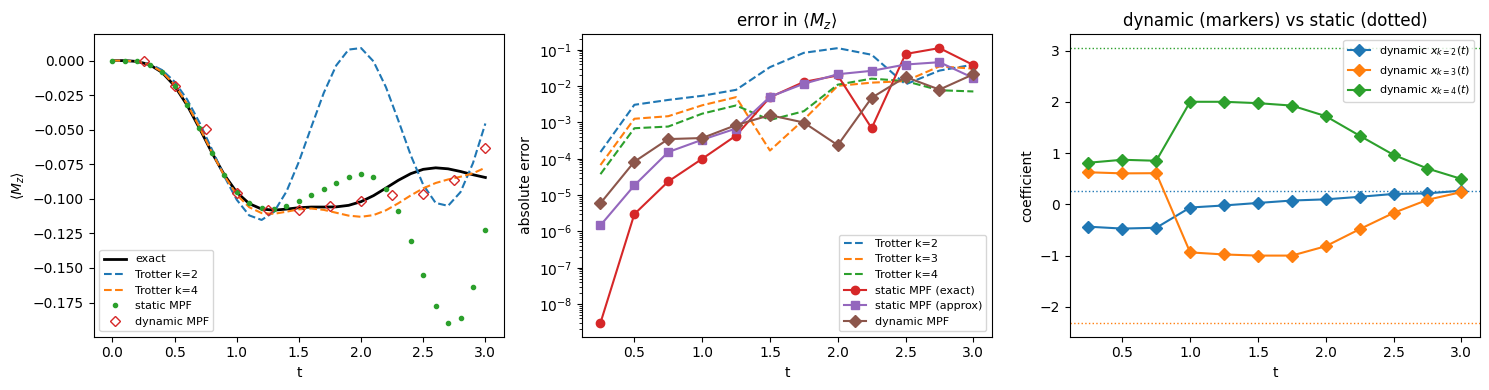

    t  best single     static    dynamic
 0.25     3.76e-05   3.01e-09   5.95e-06
 0.50     6.92e-04   2.99e-06   8.29e-05
 0.75     7.70e-04   2.37e-05   3.48e-04
 1.00     1.74e-03   9.95e-05   3.71e-04
 1.25     2.93e-03   4.35e-04   8.43e-04
 1.50     1.68e-04   4.93e-03   1.59e-03
 1.75     1.19e-03   1.30e-02   9.93e-04
 2.00     1.02e-02   1.97e-02   2.36e-04
 2.25     1.25e-02   6.92e-04   4.77e-03
 2.50     1.12e-02   7.67e-02   1.78e-02
 2.75     7.69e-03   1.11e-01   8.02e-03
 3.00     7.13e-03   3.80e-02   2.12e-02


In [12]:
idx = [int(np.argmin(np.abs(times - t))) for t in dyn_times]
evs_dyn_t = evs[idx]
mpf_dynamic = np.einsum("tj,tj->t", evs_dyn_t, dyn_coeffs)
ex_dyn_t = exact_vals[idx]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(times, exact_vals, "k-", lw=2, label="exact")
ax[0].plot(times, evs[:, 0], "--", label="Trotter k=2")
ax[0].plot(times, evs[:, -1], "--", label="Trotter k=4")
ax[0].plot(times, mpf_static, "o", ms=3, label="static MPF")
ax[0].plot(dyn_times, mpf_dynamic, "D", ms=5, mfc="none", label="dynamic MPF")
ax[0].set_xlabel("t"); ax[0].set_ylabel(r"$\langle M_z\rangle$"); ax[0].legend(fontsize=8)

for j, k in enumerate(trotter_steps):
    ax[1].semilogy(dyn_times, np.abs(evs_dyn_t[:, j] - ex_dyn_t), "--", label=f"Trotter k={k}")
ax[1].semilogy(dyn_times, np.abs(mpf_static[idx] - ex_dyn_t), "o-", label="static MPF (exact)")
ax[1].semilogy(dyn_times, np.abs(mpf_static_approx[idx] - ex_dyn_t), "s-", label="static MPF (approx)")
ax[1].semilogy(dyn_times, np.abs(mpf_dynamic - ex_dyn_t), "D-", label="dynamic MPF")
ax[1].set_xlabel("t"); ax[1].set_ylabel("absolute error"); ax[1].legend(fontsize=8)
ax[1].set_title(r"error in $\langle M_z\rangle$")

for j, k in enumerate(trotter_steps):
    ax[2].plot(dyn_times, dyn_coeffs[:, j], "D-", label=f"dynamic $x_{{k={k}}}(t)$")
    ax[2].axhline(coeffs_exact[j], color=f"C{j}", ls=":", lw=1)
ax[2].set_xlabel("t"); ax[2].set_ylabel("coefficient"); ax[2].set_title("dynamic (markers) vs static (dotted)")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'t':>5} {'best single':>12} {'static':>10} {'dynamic':>10}")
for i, t in enumerate(dyn_times):
    print(f"{t:5.2f} {np.abs(evs_dyn_t[i] - ex_dyn_t[i]).min():12.2e} "
          f"{abs(mpf_static[idx][i] - ex_dyn_t[i]):10.2e} {abs(mpf_dynamic[i] - ex_dyn_t[i]):10.2e}")

**Results** (see the table above)

* **Short times ($t\le 1.25$, so $t/k_{\min}\le 0.625$):** the **static MPF** is the most accurate method. The $k^{-2}, k^{-4}$ error expansion holds and cancels exactly. The errors are about 7 to $10^4$ times below the best single circuit. The dynamic MPF also beats every single circuit here, but by less. Its L1 bound and its Frobenius objective target the whole *state*, not one observable.
* **Intermediate times ($t=1.5$ to $2$, so $t/k_{\min}\approx 1$):** the fixed static coefficients stop working. The static error becomes *larger* than the error of the best single circuit. The **dynamic MPF** adapts $x(t)$ (right panel). Its error is about 3 to 80 times smaller than the static error. At $t=1.75$ and $t=2$ it also beats the best single circuit.
* **Long times ($t\ge 2.5$, so $t/k_{\min}\ge 1.25$):** all methods lose accuracy, because $k=(2,3,4)$ steps are too coarse. The dynamic MPF stays well conditioned ($\|x\|_1$ goes to 1) and stays below the static MPF error. For this observable, its error is larger than that of the best single circuit. The solution is larger $k_j$ (Section 6).
* The "best single" column is chosen *afterwards*, with the exact answer. For example, at $t=1.5$ the $k=3$ circuit happens to be close to the exact curve. In practice, the best $k$ is not known in advance.
* The dynamic MPF costs one classical tensor-network calculation per time point. This cost grows with entanglement, not directly with the number of qubits.

## 10. Summary and references

* A product formula with $k$ steps has an error that is a power series in $1/k$. MPFs combine several shallow circuits, $\sum_j x_j\langle O\rangle_{k_j}$, to cancel the leading terms.
* **Static MPF:** call `setup_static_lse(ks, order, symmetric)`. Then use `lse.solve()` (exact), or `setup_exact_problem` / `setup_sum_of_squares_problem(lse, max_l1_norm=...)` (bounded L1 norm). Choose $k_j$ with $t/k_{\min}\lesssim1$ and a small (re-weighted) L1 norm. A `cvxpy.Parameter` makes the scan cheap.
* **Dynamic MPF:** call `setup_dynamic_lse(...)` with a tensor-network backend, then `setup_frobenius_problem`. Here the backend is `quimb_layers.LayerwiseEvolver`, built from the same layers as the circuits. The coefficients depend on time and stay well conditioned. They keep working beyond the range of the static MPF ($t/k_{\min}\gtrsim 1$).

**Notes on the installed version (0.3.0)**

* An undecomposed `PauliEvolutionGate` is simulated as the exact exponential, so it shows no Trotter error. Workaround: decompose or transpile the Trotter circuits before simulation.
* `LayerModel.from_quantum_circuit` needs single-qubit layers split by bond parity. Workaround: create two models per single-qubit layer, with `keep_only_odd=True` and `keep_only_odd=False`.
* `LSE.solve()` raises a `ValueError` on a dynamic LSE. Workaround: use `setup_frobenius_problem` and `problem.solve()`.

## References

1. Tutorial: Reducing the Trotter error of Hamiltonian dynamics with multi-product formulas. <https://qiskit.github.io/qiskit-addon-mpf/tutorials/01_getting_started.html>
2. How-to: How to choose the Trotter steps for an MPF. <https://qiskit.github.io/qiskit-addon-mpf/how_tos/choose_trotter_steps.html>
3. How-to: How to use the approximate model. <https://qiskit.github.io/qiskit-addon-mpf/how_tos/using_approximate_model.html>
4. IBM Quantum tutorial: Multi-product formulas to reduce Trotter error. <https://quantum.cloud.ibm.com/docs/en/tutorials/multi-product-formula>
5. Explanation: Understanding the stability of MPFs. <https://qiskit.github.io/qiskit-addon-mpf/explanations/mpf_stability.html>
6. API reference: `qiskit_addon_mpf.static`. <https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.static.html>
7. API reference: `qiskit_addon_mpf.costs`. <https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.costs.html>
8. API reference: `qiskit_addon_mpf.dynamic`. <https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.dynamic.html>
9. API reference: `qiskit_addon_mpf.backends.quimb_layers`. <https://qiskit.github.io/qiskit-addon-mpf/apidocs/qiskit_addon_mpf.backends.quimb_layers.html>
10. Qiskit API reference: `PauliEvolutionGate`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.PauliEvolutionGate>
11. Qiskit API reference: `StatevectorEstimator`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator>